In [1]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import time
from tqdm import tqdm
import folium
from folium.plugins import MarkerCluster
from wordcloud import WordCloud

In [2]:
# Windows용 한글 폰트 오류 해결
from matplotlib import font_manager, rc
from pathlib import Path
font_path = "C:/Windows/Fonts/malgun.ttf"
if not Path(font_path).is_file():
    font_path = next(
        (path for path in (
            "/System/Library/Fonts/Supplemental/AppleGothic.ttf",
            "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
            "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
        ) if Path(path).is_file()),
        font_path,
    )
font_name = font_manager.FontProperties(fname = font_path).get_name()
rc("font", family = font_name)

In [3]:
raw_total = pd.read_excel("./data/crawling_raw.xlsx")

In [4]:
raw_total.head()

,content,date,like,place,tags
0,더 늦기전에 제주도로 떠나쟈😍.#제주핫플레이스 간단히 1탄 모아봄!#제주여행 요 필...,2018-12-07,"1,402",NaN,"['#제주핫플레이스', '#제주여행', '#제주여행', '#제주도여행', '#제주가..."
1,12월에 제주도를 가야하는이유🍊.#제주핫플 모음 끝판왕😍이거 하나면 겨울 #제주여행...,2018-12-03,368,NaN,"['#제주핫플', '#제주여행', '#제주', '#제주도', '#제주도맛집', '#..."
2,11월 놓치지 말아야 할 제주 관광.가을바람이 최고조에 이르는 11월추운 겨울을 앞...,2018-11-02,166,NaN,"['#honestin', '#어니스틴', '#제주여행', '#제주', '#제주도',..."
3,국민학교세대#제주관광#제주살이#제주이주민#아라동주민#삼남매집 #새해첫날#드라이브#명...,2019-01-01,28,명월국민학교,"['#제주관광', '#제주살이', '#제주이주민', '#아라동주민', '#삼남매집'..."
4,#제주관광 #제주 #돔나이트 #스트레스 #풀자 #춤추며 #땀날려 #가끔은괜찮아 #인...,2019-01-01,12,NaN,"['#제주관광', '#제주', '#돔나이트', '#스트레스', '#풀자', '#춤추..."


In [5]:
raw_total["tags"].head()

0    ['#제주핫플레이스', '#제주여행', '#제주여행', '#제주도여행', '#제주가...
1    ['#제주핫플', '#제주여행', '#제주', '#제주도', '#제주도맛집', '#...
2    ['#honestin', '#어니스틴', '#제주여행', '#제주', '#제주도',...
3    ['#제주관광', '#제주살이', '#제주이주민', '#아라동주민', '#삼남매집'...
4    ['#제주관광', '#제주', '#돔나이트', '#스트레스', '#풀자', '#춤추...
Name: tags, dtype: object

In [12]:
raw_total.loc[0, "tags"]

"['#제주핫플레이스', '#제주여행', '#제주여행', '#제주도여행', '#제주가볼만한곳', '#제주도핫플', '#제주여행코스', '#제주공항', '#제주도맛집', '#제주맛집', '#제주스냅', '#제주풍경', '#제주사진', '#제주카페', '#제주도카페', '#산굼부리', '#제주도바다', '#귤체험', '#우도', '#제주관광', '#제주도여향지', '#제주여행중', '#삼육오빠', '#제주앓이']"

In [18]:
eval(raw_total.loc[0, "tags"])

['#제주핫플레이스',
 '#제주여행',
 '#제주여행',
 '#제주도여행',
 '#제주가볼만한곳',
 '#제주도핫플',
 '#제주여행코스',
 '#제주공항',
 '#제주도맛집',
 '#제주맛집',
 '#제주스냅',
 '#제주풍경',
 '#제주사진',
 '#제주카페',
 '#제주도카페',
 '#산굼부리',
 '#제주도바다',
 '#귤체험',
 '#우도',
 '#제주관광',
 '#제주도여향지',
 '#제주여행중',
 '#삼육오빠',
 '#제주앓이']

In [19]:
# 해시태그 통합 저장
tags_total = []

for tag in raw_total["tags"]:
    # str을 리스트로 변환
    tag = eval(tag)
    tags_total.extend(tag)

## 해시태그 출현 빈도

In [22]:
# 그룹 내 원소의 종류별 빈도수를 집계
tag_counts = Counter(tags_total)

In [23]:
# 가장 빈도수가 높은 해시태그 50개
tag_counts.most_common(50)

[('#제주맛집', 3750),
 ('#제주도맛집', 3467),
 ('#제주여행', 3204),
 ('#제주관광', 2898),
 ('#제주도', 2096),
 ('#제주', 1567),
 ('#제주도여행', 1556),
 ('#서귀포맛집', 1392),
 ('#제주도가볼만한곳', 1047),
 ('#서귀포', 872),
 ('#제주핫플레이스', 848),
 ('#jeju', 776),
 ('#제주흑돼지맛집', 730),
 ('#제주맛집추천', 728),
 ('#일상', 717),
 ('#제주도흑돼지', 713),
 ('#제주카페', 711),
 ('#제주도흑돼지맛집', 709),
 ('#제주흑돼지', 693),
 ('#협재맛집', 677),
 ('#성산일출봉', 674),
 ('#제주도민', 637),
 ('#제주도그램', 609),
 ('#서귀포흑돼지맛집', 605),
 ('#서귀포흑돼지', 582),
 ('#제주가볼만한곳', 580),
 ('#성산일출봉맛집', 567),
 ('#섭지코지', 558),
 ('#제주도민맛집', 542),
 ('#제주핫플', 530),
 ('#선팔', 522),
 ('#섭지코지맛집', 519),
 ('#제주살이', 516),
 ('#여행스타그램', 498),
 ('#통갈치구이', 495),
 ('#제주통갈치구이', 485),
 ('#제주서귀포맛집', 479),
 ('#제주반영구', 478),
 ('#중문맛집', 472),
 ('#제주눈썹문신', 472),
 ('#제주도관광', 471),
 ('#서귀포눈썹문신', 458),
 ('#여행', 455),
 ('#먹스타그램', 453),
 ('#제주시', 451),
 ('#반영구', 443),
 ('#눈썹문신', 443),
 ('#제주자연눈썹', 435),
 ('#제주속눈썹', 435),
 ('#서귀포남자눈썹문신', 433)]

In [28]:
# 제주도 관광/맛집 과 관계없는 해시태그 제외
STOPWORDS = ['#일상',
             '#제주도',
             '#제주',
             '#jeju',
             '#선팔',
             '#반영구',
             '#눈썹문신',
             '#제주자연눈썹',
             '#제주속눈썹',
             '#서귀포남자눈썹문신',
             '#제주메이크업',
             '#맞팔',
             '#소통',
             '#서귀포반영구',
             '#서귀포속눈썹',
             '#제주남자눈썹문신',
             '#서귀포자연눈썹',
             '#서귀포눈썹문신',
             '#제주눈썹문신']

In [29]:
tag_total_selected = [tag for tag in tags_total if tag not in STOPWORDS]

In [30]:
tag_counts_selected = Counter(tag_total_selected)

In [31]:
tag_counts_selected.most_common(50)

[('#제주맛집', 3750),
 ('#제주도맛집', 3467),
 ('#제주여행', 3204),
 ('#제주관광', 2898),
 ('#제주도여행', 1556),
 ('#서귀포맛집', 1392),
 ('#제주도가볼만한곳', 1047),
 ('#서귀포', 872),
 ('#제주핫플레이스', 848),
 ('#제주흑돼지맛집', 730),
 ('#제주맛집추천', 728),
 ('#제주도흑돼지', 713),
 ('#제주카페', 711),
 ('#제주도흑돼지맛집', 709),
 ('#제주흑돼지', 693),
 ('#협재맛집', 677),
 ('#성산일출봉', 674),
 ('#제주도민', 637),
 ('#제주도그램', 609),
 ('#서귀포흑돼지맛집', 605),
 ('#서귀포흑돼지', 582),
 ('#제주가볼만한곳', 580),
 ('#성산일출봉맛집', 567),
 ('#섭지코지', 558),
 ('#제주도민맛집', 542),
 ('#제주핫플', 530),
 ('#섭지코지맛집', 519),
 ('#제주살이', 516),
 ('#여행스타그램', 498),
 ('#통갈치구이', 495),
 ('#제주통갈치구이', 485),
 ('#제주서귀포맛집', 479),
 ('#제주반영구', 478),
 ('#중문맛집', 472),
 ('#제주도관광', 471),
 ('#여행', 455),
 ('#먹스타그램', 453),
 ('#제주시', 451),
 ('#제주스타그램', 432),
 ('#제주일상', 424),
 ('#애월맛집', 410),
 ('#제주시맛집', 387),
 ('#카멜리아힐', 384),
 ('#중문흑돼지맛집', 377),
 ('#daily', 362),
 ('#제주도여행코스', 361),
 ('#가족여행', 357),
 ('#제주도카페', 354),
 ('#jejuisland', 348),
 ('#제주속눈썹연장', 343)]

### 막대차트

In [32]:
# 시각화용 데이터 준비
tag_counts_df = pd.DataFrame(tag_counts_selected.most_common(30))
tag_counts_df.columns = ["tags", "counts"]

In [33]:
tag_counts_df.head()

,tags,counts
0,#제주맛집,3750
1,#제주도맛집,3467
2,#제주여행,3204
3,#제주관광,2898
4,#제주도여행,1556


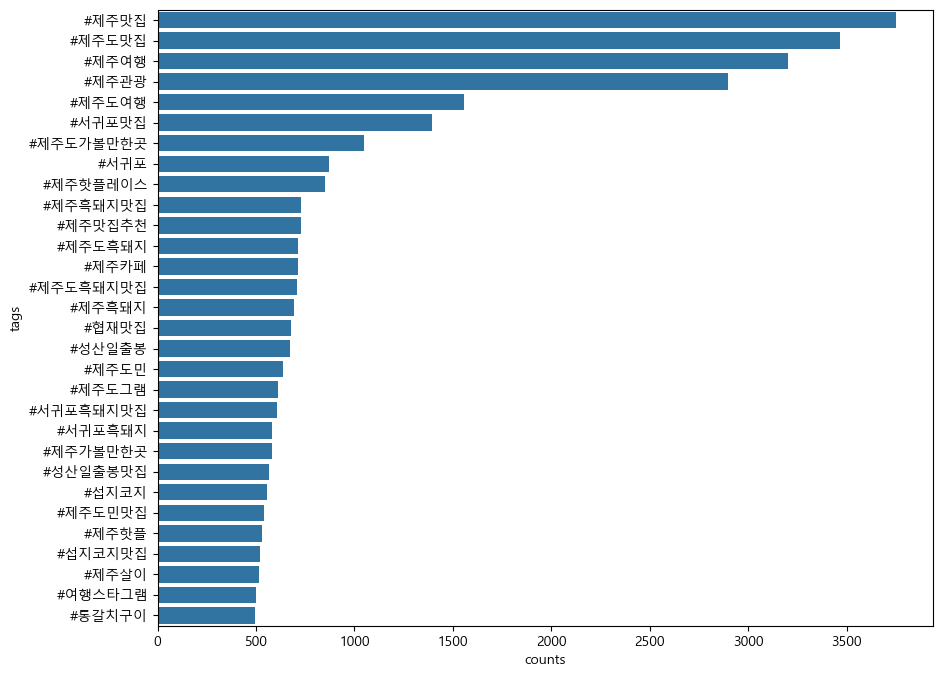

In [34]:
plt.figure(figsize = (10, 8))
sns.barplot(x = "counts", y = "tags", data = tag_counts_df)
plt.show()

### 워드클라우드

In [35]:
wordcloud = WordCloud(
    font_path = font_path,
    background_color = "white", # 배경색
    max_words = 100, # 최대 몇 개의 단어를 나타낼 것인지 설정
    # 워드클라우드 내 글자들의 상대적인 크기(0 ~ 1)
    # 0에 가까울수록 순위, 1에 가까울수록 빈도수에 영향을 받음
    relative_scaling = 0.3, 
    width = 800,
    height = 400
).generate_from_frequencies(tag_counts_selected)

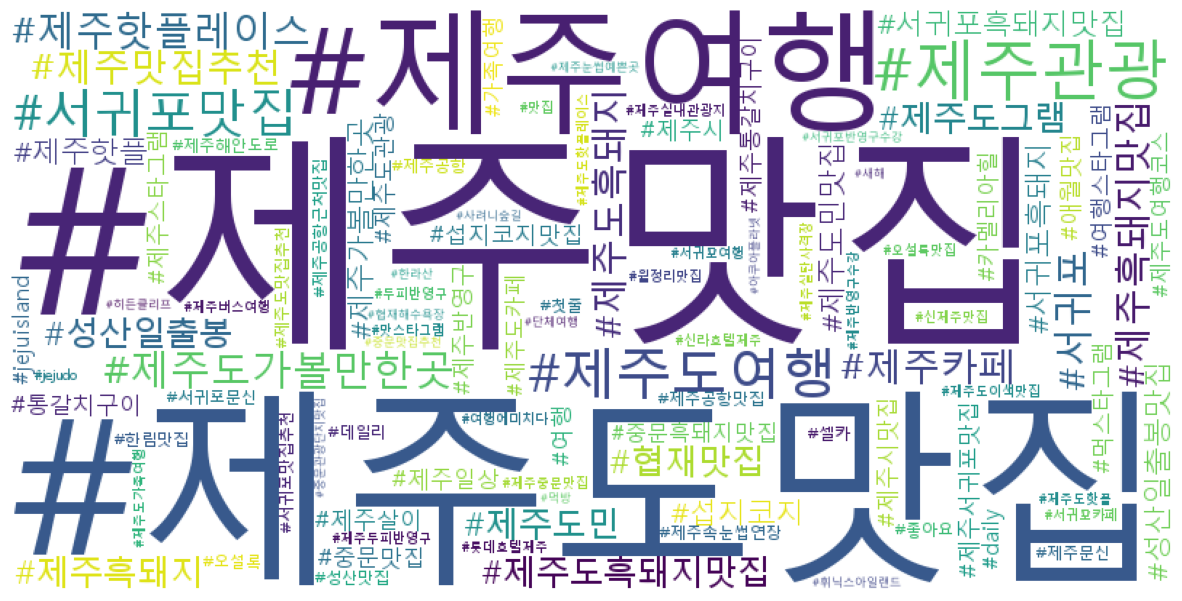

In [36]:
plt.figure(figsize = (15, 10))
plt.imshow(wordcloud)
plt.axis("off")
plt.savefig("tag-wordcloud.png") # 시각화 파일 저장
plt.show()

### 지도 시각화

In [37]:
raw_total.head()

,content,date,like,place,tags
0,더 늦기전에 제주도로 떠나쟈😍.#제주핫플레이스 간단히 1탄 모아봄!#제주여행 요 필...,2018-12-07,"1,402",NaN,"['#제주핫플레이스', '#제주여행', '#제주여행', '#제주도여행', '#제주가..."
1,12월에 제주도를 가야하는이유🍊.#제주핫플 모음 끝판왕😍이거 하나면 겨울 #제주여행...,2018-12-03,368,NaN,"['#제주핫플', '#제주여행', '#제주', '#제주도', '#제주도맛집', '#..."
2,11월 놓치지 말아야 할 제주 관광.가을바람이 최고조에 이르는 11월추운 겨울을 앞...,2018-11-02,166,NaN,"['#honestin', '#어니스틴', '#제주여행', '#제주', '#제주도',..."
3,국민학교세대#제주관광#제주살이#제주이주민#아라동주민#삼남매집 #새해첫날#드라이브#명...,2019-01-01,28,명월국민학교,"['#제주관광', '#제주살이', '#제주이주민', '#아라동주민', '#삼남매집'..."
4,#제주관광 #제주 #돔나이트 #스트레스 #풀자 #춤추며 #땀날려 #가끔은괜찮아 #인...,2019-01-01,12,NaN,"['#제주관광', '#제주', '#돔나이트', '#스트레스', '#풀자', '#춤추..."


In [38]:
raw_total.shape

(8801, 5)

In [39]:
raw_total.dtypes

content    object
date       object
like       object
place      object
tags       object
dtype: object

In [40]:
raw_total.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8801 entries, 0 to 8800
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  8801 non-null   object
 1   date     8801 non-null   object
 2   like     8801 non-null   object
 3   place    2953 non-null   object
 4   tags     8801 non-null   object
dtypes: object(5)
memory usage: 343.9+ KB


#### 위치 정보 정리

In [41]:
location_counts = raw_total["place"].value_counts()

In [42]:
location_counts

place
Jeju                    271
Jeju-do                 179
Jungle Book by Alice    108
Seogwipo                 66
제주도 크리스마스 박물관            59
                       ... 
제주마당                      1
형제섬                       1
동복해녀식당                    1
종로 광장시장                   1
디스이즈핫                     1
Name: count, Length: 1028, dtype: int64

In [43]:
location_counts_df = pd.DataFrame(location_counts)

In [44]:
location_counts_df.head()

,count
place,
Jeju,271
Jeju-do,179
Jungle Book by Alice,108
Seogwipo,66
제주도 크리스마스 박물관,59


#### 카카오api 로 위경도 받아오기

In [48]:
import os
url = "https://dapi.kakao.com/v2/local/search/keyword.json"

headers = {"Authorization" : f"KakaoAK {os.getenv('KAKAO_REST_API_KEY')}"}

params = {"query" : "코리아it신촌"}

places = requests.get(url, headers = headers, params = params)

In [50]:
data = places.json()

In [54]:
data["documents"][0]["place_name"]

'코리아IT아카데미 신촌점'

In [55]:
data["documents"][0]["x"]

'126.93578664586859'

In [56]:
data["documents"][0]["y"]

'37.554041546037986'

In [57]:
def find_places(searching):
    url = "https://dapi.kakao.com/v2/local/search/keyword.json"

    headers = {"Authorization" : f"KakaoAK {os.getenv('KAKAO_REST_API_KEY')}"}
    
    params = {"query" : searching}
    
    res = requests.get(url, headers = headers, params = params)

    # 필요한 정보 추출
    place = res.json()["documents"][0]

    name = place["place_name"]
    x = place["x"]
    y = place["y"]

    return [name, x, y, searching]

In [58]:
# 함수 테스트
data = find_places("제주공항")
data

['제주국제공항', '126.49272304493574', '33.50683984835887', '제주공항']

In [59]:
len(location_counts_df.index)

1028

#### 인스타그램 위치 좌표 수집

In [60]:
location_inform = []

for location in tqdm(location_counts_df.index):
    # 검색 결과가 나오지 않는 곳도 있음
    try:
        data = find_places(location)
        location_inform.append(data)
        time.sleep(0.1)

    except IndexError as e:
        print(location)

  0%|▏                                                                                | 3/1028 [00:00<01:36, 10.66it/s]

Jeju-do
Jungle Book by Alice


  1%|▋                                                                                | 8/1028 [00:01<02:07,  8.00it/s]

제주에인감귤밭


  1%|▊                                                                               | 10/1028 [00:01<01:44,  9.77it/s]

성산일출봉 城山日出峰  Seongsan Ilchulbong
폼포코식당_pompokokitchen


... (385 outputs left out)

알동네국수
Villadeato-빌라드아토
목포고을. 제주도 흑돼지 끝나는 맛!


 99%|█████████████████████████████████████████████████████████████████████████████▍| 1020/1028 [02:17<00:00, 10.49it/s]

하이클래스 제주 (Hiclass Jeju)
모닝딜라이트제주광양점


100%|██████████████████████████████████████████████████████████████████████████████| 1028/1028 [02:19<00:00,  7.39it/s]


In [61]:
location_inform[:5]

[['R고기 in Jeju', '126.46542934219148', '33.503587560005954', 'Jeju'],
 ['서귀포잠수함', '126.558616052674', '33.2393033784206', 'Seogwipo'],
 ['바이나흐튼 크리스마스박물관',
  '126.32779866033343',
  '33.29131209935493',
  '제주도 크리스마스 박물관'],
 ['할로비치', '127.020825988861', '37.5182108620338', '할로비치'],
 ['제주도', '126.54587355630036', '33.379777816446165', 'Jeju Island']]

In [62]:
# 위치 정보 저장
location_inform_df = pd.DataFrame(location_inform)
location_inform_df.columns = ["카카오지도위치명", "경도", "위도", "인스타위치명"]

In [63]:
location_inform_df.head()

,카카오지도위치명,경도,위도,인스타위치명
0,R고기 in Jeju,126.46542934219148,33.503587560005954,Jeju
1,서귀포잠수함,126.558616052674,33.2393033784206,Seogwipo
2,바이나흐튼 크리스마스박물관,126.32779866033343,33.29131209935493,제주도 크리스마스 박물관
3,할로비치,127.020825988861,37.5182108620338,할로비치
4,제주도,126.54587355630036,33.379777816446165,Jeju Island


In [64]:
location_counts_df.head()

,count
place,
Jeju,271
Jeju-do,179
Jungle Book by Alice,108
Seogwipo,66
제주도 크리스마스 박물관,59


#### 위치 정보별 인스타 게시량

In [65]:
location_data = pd.merge(location_inform_df, location_counts_df, left_on = "인스타위치명",
                         right_index = True) # location_counts_df에서는 인덱스를 기준으로 병합

In [66]:
location_data.head()

,카카오지도위치명,경도,위도,인스타위치명,count
0,R고기 in Jeju,126.46542934219148,33.503587560005954,Jeju,271
1,서귀포잠수함,126.558616052674,33.2393033784206,Seogwipo,66
2,바이나흐튼 크리스마스박물관,126.32779866033343,33.29131209935493,제주도 크리스마스 박물관,59
3,할로비치,127.020825988861,37.5182108620338,할로비치,51
4,제주도,126.54587355630036,33.379777816446165,Jeju Island,40


In [67]:
location_data["카카오지도위치명"].value_counts()

카카오지도위치명
제주동문시장                 4
세화해변                   3
자매국수                   3
올레길 6코스(쇠소깍-서귀포 올레)    3
협재해수욕장                 3
                      ..
대천해수욕장                 1
도라지식당                  1
호박다방                   1
삼원정 본점                 1
디스이즈핫                  1
Name: count, Length: 690, dtype: int64

In [71]:
location_data[location_data["카카오지도위치명"] == "올레길 6코스(쇠소깍-서귀포 올레)"]

,카카오지도위치명,경도,위도,인스타위치명,count
412,올레길 6코스(쇠소깍-서귀포 올레),126.58182615491253,33.243790752367175,올레 6코스 (Olle Route 6),1
535,올레길 6코스(쇠소깍-서귀포 올레),126.58182615491253,33.243790752367175,보목,1
597,올레길 6코스(쇠소깍-서귀포 올레),126.58182615491253,33.243790752367175,올레길,1


In [75]:
# 장소 이름 기준 병합(중복 제거)
location_data = location_data.groupby(["카카오지도위치명", "경도", "위도"])[["count"]].sum()

In [76]:
location_data.head()

,,,count
카카오지도위치명,경도,위도,
1158족욕카페,126.33649979086103,33.46707849152644,1
73st,126.45510883544576,33.45699074238026,1
CU 수원광장점,127.000144309653,37.26812040180812,1
KBS 본관,126.91674992301569,37.52470211311498,1
MASJID ATTAUBAH SEOSAN,126.456420317236,36.7814052783056,1


In [77]:
location_data = location_data.reset_index()

In [78]:
location_data.head()

,카카오지도위치명,경도,위도,count
0,1158족욕카페,126.33649979086103,33.46707849152644,1
1,73st,126.45510883544576,33.45699074238026,1
2,CU 수원광장점,127.000144309653,37.26812040180812,1
3,KBS 본관,126.91674992301569,37.52470211311498,1
4,MASJID ATTAUBAH SEOSAN,126.456420317236,36.7814052783056,1


#### 지도 시각화

In [79]:
Mt_Hanla = [33.3625, 126.533694]
map_jeju = folium.Map(location = Mt_Hanla, zoom_start = 11)

In [80]:
map_jeju

In [81]:
for i in range(len(location_data)):
    name = location_data["카카오지도위치명"][i] # 공식 명칭
    count = location_data["count"][i] # 게시글 개수
    size = int(count) * 2
    lng = float(location_data["위도"][i])
    lat = float(location_data["경도"][i])
    folium.CircleMarker((lng, lat), radius = size, color = "red", popup = name).add_to(map_jeju)

In [82]:
map_jeju

#### 그룹으로 지도 시각화

- 서클마커는 특정 지역에 너무 몰려있을 경우 개별 위치를 확인하기 어려움
    - 인접한 서클마커들끼리 그룹으로 묶어서 표현

In [83]:
locations = []
names = []

for i in range(len(location_data)):
    data = location_data.iloc[i]
    locations.append((float(data["위도"]), float(data["경도"])))
    names.append(data["카카오지도위치명"])

map_jeju2 = folium.Map(location = Mt_Hanla, zoom_start = 11)

In [84]:
locations[:5]

[(33.46707849152644, 126.33649979086103),
 (33.45699074238026, 126.45510883544576),
 (37.26812040180812, 127.000144309653),
 (37.52470211311498, 126.91674992301569),
 (36.7814052783056, 126.456420317236)]

In [85]:
names[:5]

['1158족욕카페', '73st', 'CU 수원광장점', 'KBS 본관', 'MASJID ATTAUBAH SEOSAN']

In [86]:
marker_cluster = MarkerCluster(
    locations = locations,
    popups = names,
    name = "jeju",
    overlay = True,
    control = True
)

marker_cluster.add_to(map_jeju2)
folium.LayerControl().add_to(map_jeju2)

In [87]:
map_jeju2